<div style="background-color:rgb(100, 110, 220); padding:10px;">

## Day 5: Mixed general ML:

- **Data Preprocessing**
  - Feature Selection -- reduce dimensionality
  - Advance feature engineering
 

- **Machine Learning Algorithms**
  - Advanced regression and Classification (Support Vector Machines, Decision tree)
- **Model Selection and Evaluation**
   - Counterfactuals: what ifs: deeper evaluation of models:
   - SHAP, LIME



### Dataset:  wines_binary.csv and fish_no_pikes.csv
### libraries: pandas, scikit learn, matplotlib, and seaborn



In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('../Lecture_data/wines_binary.csv')
y = df['is_good_quality']
X = df.drop(columns=['is_good_quality'])
X_development, X_test, y_development, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_development, y_development, test_size=0.25,
    random_state=42, stratify=y_development)

# 1. Data Preprocessing


## 1.1. Reducing Data Complexity through Feature Selection

Feature selection is a crucial step in machine learning that helps identify and select the most relevant features for building the model. This 
- reduces the complexity of the model,
- can improve performance (check on validation data),
- reduces Training Time
- and can prevent overfitting.

### Feature Selection Techniques

- **Domain Knowledge**:
  We have previously utilized domain knowledge in our exercises to evaluate the relevance and balance of features. By understanding the information each feature provides, we can identify and eliminate unnecessary features.

- **Feature Correlation**:
  One technique for feature selection is to remove one or more features that are highly correlated with each other. This can reduce redundancy; its effect on predictive performance must be checked.

In [2]:
corr = X_train.corr()
corr

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,sulphates,alcohol
fixed acidity,1.000000,0.616307,0.181648,0.142641,-0.012997,-0.002246,-0.001338,0.002580,-0.002990,0.111802
volatile acidity,0.616307,1.000000,0.783643,0.287521,0.598224,-0.008312,-0.000044,0.000303,-0.006306,0.643110
citric acid,0.181648,0.783643,1.000000,0.339403,0.571413,-0.005150,0.002818,-0.002324,-0.004152,0.333574
residual sugar,0.142641,0.287521,0.339403,1.000000,-0.361395,0.003085,0.008259,-0.001703,-0.004631,0.027155
chlorides,-0.012997,0.598224,0.571413,-0.361395,1.000000,-0.012567,-0.002422,-0.001478,-0.001657,0.726014
free sulfur dioxide,-0.002246,-0.008312,-0.005150,0.003085,-0.012567,1.000000,0.000797,0.003733,-0.001321,-0.012046
total sulfur dioxide,-0.001338,-0.000044,0.002818,0.008259,-0.002422,0.000797,1.000000,0.007617,0.001965,-0.001456
density,0.002580,0.000303,-0.002324,-0.001703,-0.001478,0.003733,0.007617,1.000000,0.004209,-0.000588
sulphates,-0.002990,-0.006306,-0.004152,-0.004631,-0.001657,-0.001321,0.001965,0.004209,1.000000,-0.006120
alcohol,0.111802,0.643110,0.333574,0.027155,0.726014,-0.012046,-0.001456,-0.000588,-0.006120,1.000000


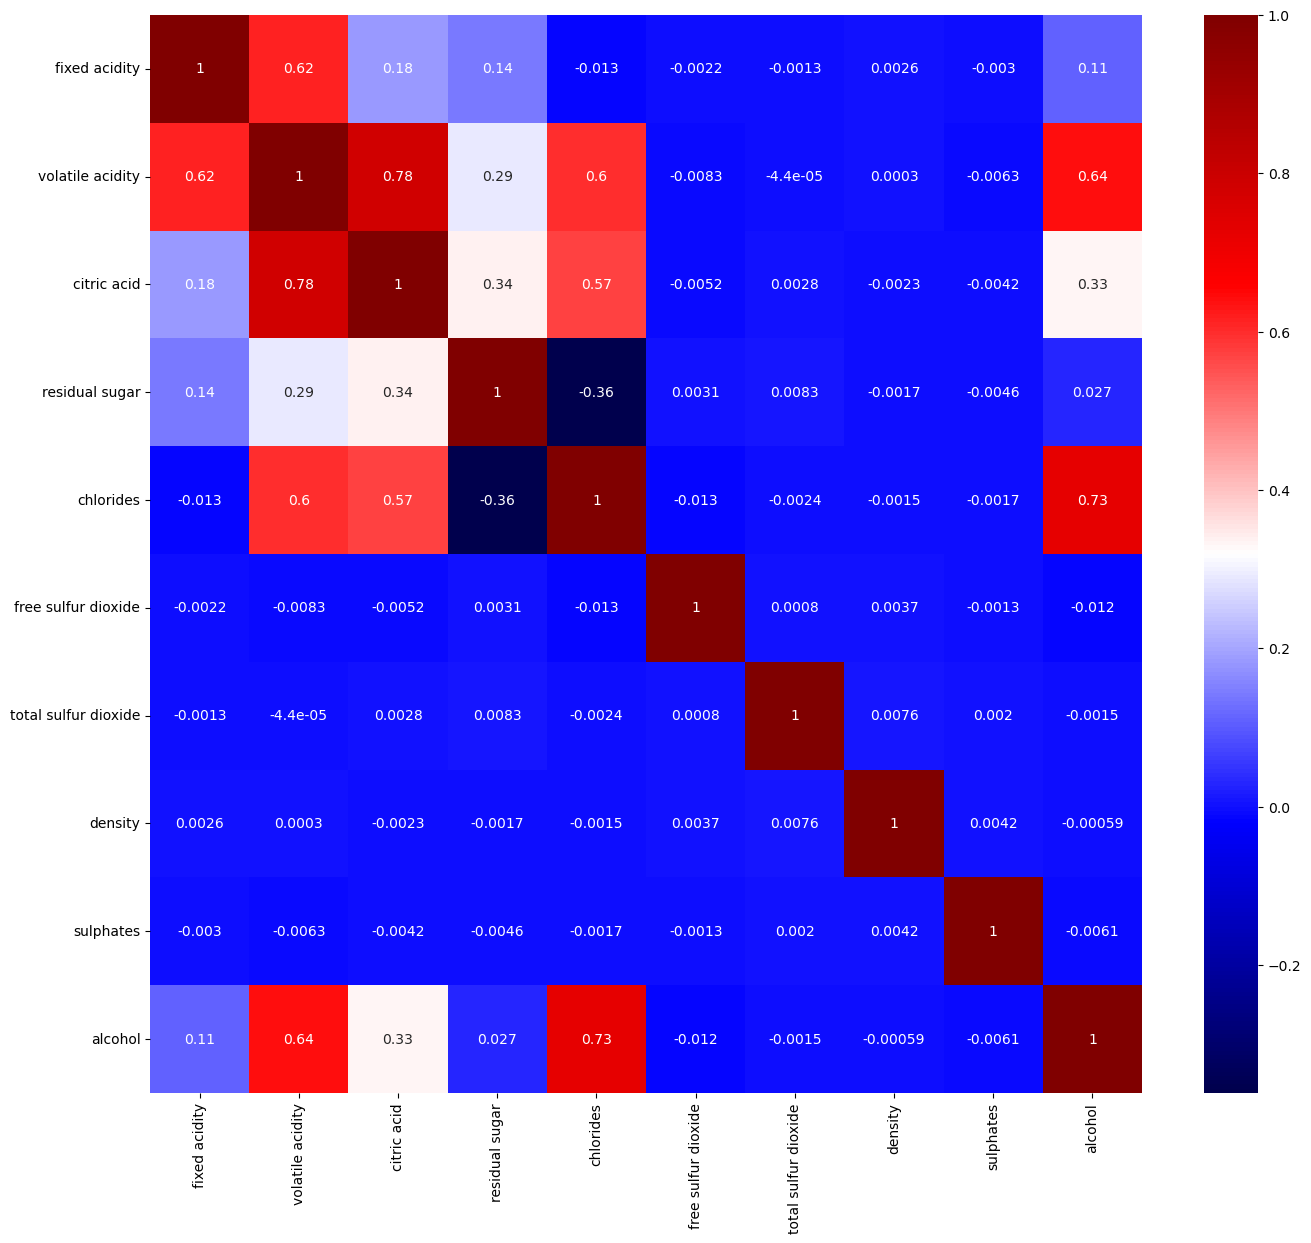

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,1, figsize=(16,14))

sns.heatmap(corr, 
        xticklabels=corr.columns,
        yticklabels=corr.columns,
        cmap= "seismic",ax=ax, annot=corr);

## General Rule of Thumb
- Consider pairs with absolute correlation above 0.75, but do not drop features automatically.
- Use domain knowledge and validation to decide whether removal helps. Correlated predictors can share information, making individual importance scores difficult to interpret.

In [4]:
X_train = X_train.drop(columns=['citric acid', 'chlorides'])
X_val = X_val.drop(columns=['citric acid', 'chlorides'])
X_test = X_test.drop(columns=['citric acid', 'chlorides'])

### Feature Permutation
Fit a model and record its score on validation data. Shuffle **one** feature, score again, and repeat for each feature. The drop in score measures this fitted model's reliance on that feature.

Keep the final test set out of feature selection. Correlated features can substitute for one another, so a small drop does not prove that a feature is irrelevant.

[Sklearn's `permutation_importance` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html)

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=3000))])

In [6]:
permutation_score = permutation_importance(
    model, X_val, y_val, n_repeats=10, random_state=42, scoring='accuracy')

In [7]:
import numpy as np
importance_df = pd.DataFrame(np.vstack((X_train.columns,
                                        permutation_score.importances_mean)).T) # Unstack results
importance_df.columns=['feature','score decrease']

importance_df.sort_values(by="score decrease", ascending = False) # Order by importance

,feature,score decrease
1,volatile acidity,0.40681
7,alcohol,0.02196
0,fixed acidity,0.01391
2,residual sugar,0.002075
5,density,0.000345
6,sulphates,0.00028
4,total sulfur dioxide,0.00022
3,free sulfur dioxide,-0.000055


`sulphates`, `total sulfur dioxide`, `density`, and `residual sugar` all have very small score decreases. You might consider dropping them if you want to further reduce dimensionality, though their effects are not entirely negligible. However, since their score decreases are close to 0, dropping them might not hurt model performance significantly.


In [8]:
# A candidate subset to investigate; this is not a validated final model.
candidate_features = ['fixed acidity', 'volatile acidity', 'alcohol']
X_train_reduced = X_train[candidate_features]

# 2. Machine Learning Algorithms: Advanced regression and Classification

In this section, we will focus on three advanced classification algorithms that are widely used in machine learning:

- Support Vector Machines (SVM)
- Decision Trees

<div style="background-color:rgba(60, 179, 113, 0.3); padding:10px;">

## 2.1 Support Vector Machines (SVM)
A linear SVM balances a large margin with penalties for margin violations. A kernel SVM uses inner products in a feature space to learn a nonlinear boundary without explicitly constructing every transformed feature.

**Key Concepts:**
- **Support vectors:** Observations with nonzero dual coefficients. In a soft-margin SVM they may lie on the margin, inside it, or on the wrong side of the boundary.
- **Margin:** For a binary linear SVM, the planes $w^Tx+b=\pm1$ are separated by $2/\|w\|$. Points may violate this margin.
- **Kernel:** Linear, polynomial and RBF kernels imply different notions of similarity.
- **Parameter C:** Larger $C$ penalises margin violations more strongly relative to the margin term; smaller $C$ allows more violations. Neither setting guarantees perfect training classification.

**Multiclassification:** OvR fits one classifier per class; OvO fits one per pair. Scikit-learn's `SVC` trains with OvO even when its decision scores are presented in OvR form.

</div>

### Support Vectors and Margins

<img src="../imgs/SVM_classifier.jpg" alt="Description" style="width: 1400px;"/>


### Kernel trick

<img src="../imgs/SVM_Kernels.jpg" alt="Description" style="width: 1400px;"/>


### Parameter C

<img src="../imgs/SVM_C.jpg" alt="Description" style="width: 1400px;"/>


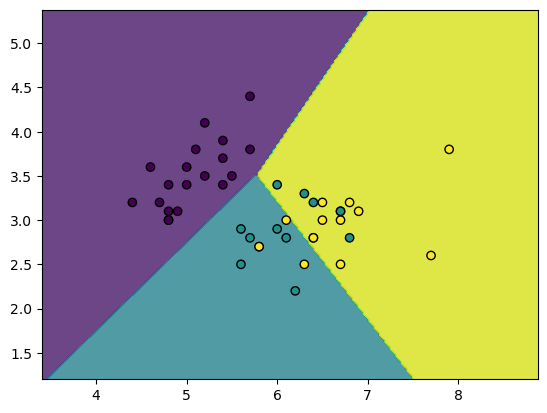

In [9]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
import matplotlib.pyplot as plt

# Load dataset
iris = datasets.load_iris()
X = iris.data[:, :2]  # We only take the first two features for simplicity
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Train the SVM model
model = SVC(kernel='linear')
model.fit(X_train, y_train)

# Plot decision boundary
import numpy as np

def plot_decision_boundary(X, y, model):
    h = .02  # step size in the mesh
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.8)
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o')
    plt.show()

plot_decision_boundary(X_test, y_test, model)


**For more see [multiclassification](../Dive_deeper/multiclassification.ipynb) and [SVM](../Dive_deeper/SVM.html)**


#### Example on SVM

In [9]:
## data preprocessing:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

import pandas as pd
data = pd.read_csv('../Lecture_data/fish_no_pikes.csv')


X = data.drop(columns=['Species'])
y = data['Species']

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

numeric_features = ['Weight', 'Length1', 'Length2', 'Length3', 'Height', 'Width']
numeric_transformer = StandardScaler()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features)
    ])

In [10]:
from sklearn.svm import SVC

svc = Pipeline([
    ('preprocessor', preprocessor),
    ('model', SVC(kernel='linear', C=10))
])
svc.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Weight', 'Length1',
                                                   'Length2', 'Length3',
                                                   'Height', 'Width'])])),
                ('model', SVC(C=10, kernel='linear'))])

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scores = cross_validate(svc, X_train, y_train, cv=cv,
                        scoring=['accuracy', 'f1_macro'])
for metric in ['accuracy', 'f1_macro']:
    values = scores['test_' + metric]
    print(f"CV {metric}: {values.mean():.3f} ± {values.std():.3f}")

CV accuracy: 0.832 ± 0.012
CV f1_macro: 0.686 ± 0.004


<div style="background-color:rgba(60, 179, 113, 0.3); padding:10px;">

## 2.2 Decision Trees
Decision Trees classify data by recursively splitting it based on the most significant features. The model learns rules from the training data that are represented as a tree of decisions.


#### Key Concepts

1. **Nodes, Branches, and Leaves**
   - **Root Node**: The top node representing the entire dataset.
   - **Branches**: Connections carrying observations from a split node to its children.
   - **Leaf Nodes**: Terminal nodes representing the final decision or output.

2. **Splitting Criteria**
   Decision Trees use splitting criteria to decide the best way to partition data at each node:
   
   - **Gini Impurity**: Measures the probability of incorrectly classifying a randomly chosen element from the dataset if it were labeled according to the distribution of labels at a node.
     $$
     Gini = 1 - \sum (p_i)^2
     $$
   
   - **Entropy**: Measures the amount of information or uncertainty in the data.
     $$
     Entropy = - \sum p_i \log_2 (p_i)
     $$
   
   - **Information Gain**: The reduction in entropy achieved by partitioning the data according to a given attribute. With the entropy criterion, each split greedily maximizes its weighted impurity reduction. This does not optimize the entire depth-limited tree globally.

3. **summary**

- Decision Trees split data based on features to create a flowchart-like structure of decisions.
- Scikit-learn trees require numerical inputs; encode categorical predictors first. Scaling numerical predictors is usually unnecessary.
- Regularization techniques like limiting depth and pruning help prevent overfitting.
</div>


<img src="../imgs/Tree.jpg" alt="Description" style="width: 1400px;"/>


### Decision Tree: Cinema Preference

```mermaid
graph TD;
    A[Do you love popcorn?] -->|Yes| B[Do you love soda?]
    A -->|No| C[Are you under 18?]
    B -->|Yes| D[Likes cinema]
    B -->|No| E[Are you under 18?]
    E -->|Yes| F[Likes cinema]
    E -->|No| G[Does not like cinema]
    C -->|Yes| H[Do you love soda?]
    C -->|No| I[Does not like cinema]
    H -->|Yes| J[Likes cinema]
    H -->|No| K[Does not like cinema]

```


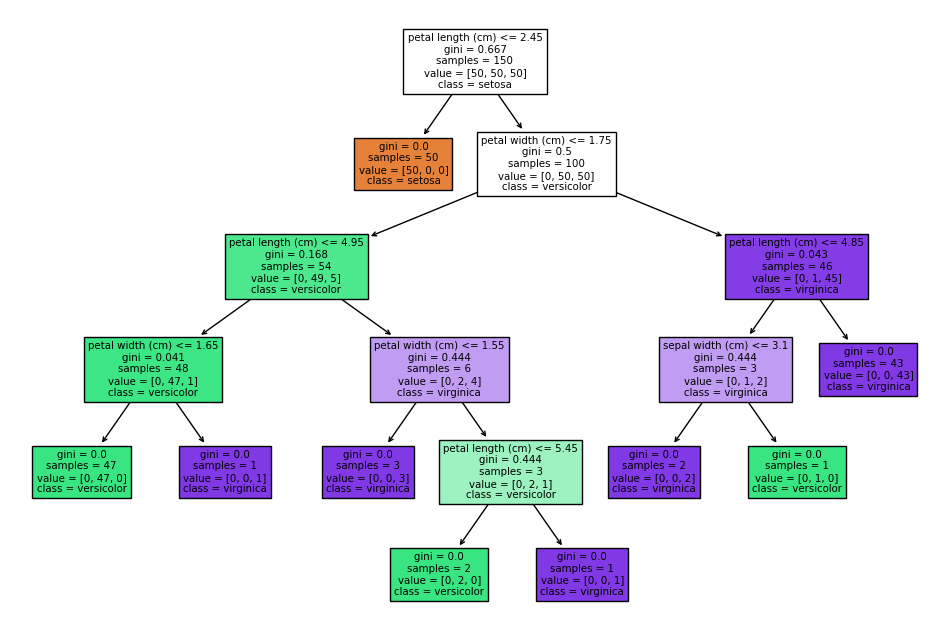

In [13]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
import matplotlib.pyplot as plt

# Load dataset
iris = load_iris()
X, y = iris.data, iris.target

# Train model
clf = DecisionTreeClassifier()
clf = clf.fit(X, y)

# Plot tree
plt.figure(figsize=(12, 8))
tree.plot_tree(clf, filled=True, feature_names=iris.feature_names, class_names=iris.target_names)
plt.show()


**For more see [Trees Notes](../Dive_deeper/Trees.pdf) and [Trees Notes](../Dive_deeper/Decision_Trees.html)**


In [14]:
## Example on decision trees: no scaling is needed.
from sklearn.tree import DecisionTreeClassifier

tree_classifier = DecisionTreeClassifier(random_state=42)
tree_classifier.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [15]:
scores = cross_validate(tree_classifier, X_train, y_train, cv=cv,
                        scoring=['accuracy', 'f1_macro'])
for metric in ['accuracy', 'f1_macro']:
    values = scores['test_' + metric]
    print(f"CV {metric}: {values.mean():.3f} ± {values.std():.3f}")

CV accuracy: 0.690 ± 0.044
CV f1_macro: 0.627 ± 0.041


## 2.3 SVM and Decision Trees as regressor


In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import pandas as pd

data = pd.read_csv('../Lecture_data/fish_no_pikes.csv')
X = data.drop(columns=['Species', 'Weight'])
y = data['Weight']  # Continuous response in grams: do not label-encode it.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [17]:
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

svr = make_pipeline(StandardScaler(), SVR(epsilon=0.1, kernel='rbf', C=1000))
tree_regressor = DecisionTreeRegressor(random_state=42)
svr.fit(X_train, y_train)
tree_regressor.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

In [18]:
# Fixed-model comparison: do not tune further using these test results.
for name, fitted_model in [('SVR', svr), ('Decision tree', tree_regressor)]:
    prediction = fitted_model.predict(X_test)
    print(f"{name}: MSE = {mean_squared_error(y_test, prediction):.2f} g²; "
          f"R² = {r2_score(y_test, prediction):.3f}")

SVR: MSE = 1598.32 g²; R² = 0.979
Decision tree: MSE = 2347.85 g²; R² = 0.969


# 3. Model Selection and Evaluation: Counterfactuals and Deeper Evaluation of Models


In this section, we focus on model interpretability using SHAP and LIME to gain deeper insights into machine learning models, particularly complex ones like random forests, neural networks, or ensembles. These tools are critical in model evaluation, helping answer “what if” or counterfactual questions to understand how small changes in input features can impact model predictions.

## Counterfactuals

Counterfactuals allow you to explore what if scenarios, such as:

- What if a certain feature value changes?
- How would the model’s prediction adjust?

## SHAP (SHapley Additive exPlanations)
SHAP assigns signed contributions relative to a reference prediction. The contributions sum to the explained prediction minus its base value in the chosen output space.

- **Local:** Explain one prediction.
- **Global:** Summarise attribution magnitudes across observations.
- **Methods:** Model-agnostic estimators are available; TreeSHAP uses tree structure for efficient calculation.
- **Assumptions:** Background data and the treatment of dependent features affect the attribution.

The Shapley axioms concern allocation of model output. They do not establish causal effects or fairness to people. Use explanations to investigate models alongside predictive validation and appropriate fairness analyses.

## LIME (Local Interpretable Model-Agnostic Explanations)
LIME perturbs inputs and fits a simple, locally weighted surrogate to the model's predictions near one observation.

The explanation depends on the perturbations, neighbourhood and surrogate. Check its local fidelity and whether the perturbed inputs are plausible. A coefficient describes this approximation, not a causal effect.
- **Human-Readable Explanations**: LIME provides easily understandable local models that explain complex predictions.
- **Surrogate Model**: Uses a simple model to approximate predictions near the data point being explained.

### Use Cases:

- **Single Prediction Explanations**: Ideal for explaining and justifying individual outcomes.
- **Model Debugging**: Spot areas where the model behaves unexpectedly.
- **Comparing Models**: Understand differences in predictions between models.

## Comparison of SHAP and LIME

| Aspect | SHAP | LIME |
|---|---|---|
| Main output | Additive feature attributions relative to a reference | Locally fitted interpretable surrogate |
| Scope | Individual predictions and summaries across observations | Local neighbourhood |
| Important choices | Background data; feature dependence; output scale | Perturbation distribution; locality; surrogate |
| Caution | Attribution is model- and reference-dependent | Explanation may change with neighbourhood or random sampling |

Both can help investigate unexpected predictions. Neither replaces held-out evaluation, causal analysis or a fairness assessment.

# FAQ: 


<div style="background-color:rgba(75, 0, 130, 0.3); padding:10px;">


**1. What are other Feature Selection Techniques**

#### 1. Filter Methods
These methods apply a statistical measure to assign a scoring to each feature. The features are ranked by the score and either selected to be kept or removed from the dataset. Examples include:
- **Chi-Square Test**
- **ANOVA**
- **Correlation Coefficient**

#### 2. Wrapper Methods
These methods consider the selection of a set of features as a search problem. They evaluate different combinations of features and select the best performing subset. Examples include:
- **Recursive Feature Elimination (RFE)**
- **Forward Selection**
- **Backward Elimination**

#### 3. Embedded Methods
These methods perform feature selection during the model training process. They are specific to certain learning algorithms and take advantage of their properties. Examples include:
- **LASSO (Least Absolute Shrinkage and Selection Operator)**
- **Ridge generally shrinks coefficients without selecting a subset.**
- **Decision Trees**

#### 4. Dimensionality Reduction
Although not strictly a feature selection method, dimensionality reduction techniques like Principal Component Analysis (PCA) and Linear Discriminant Analysis (LDA) can be used to reduce the number of features by transforming them into a lower-dimensional space.

#### 5. Feature Permutation 
Permutation importance measures a fitted model's reliance on each feature. Selecting features from it requires separate validation.


**2. Compare KNN, SVM, and Decision tree?**

Comparing the Algorithms
Each algorithm has its strengths and weaknesses. Here's a quick comparison:

| Algorithm      | Strengths                                           | Weaknesses                                          |
|----------------|-----------------------------------------------------|-----------------------------------------------------|
| SVM            | Can work well in high-dimensional spaces; regularization controls margin violations | Sensitive to scaling, kernel/C choices and potentially outliers; kernel fits can be expensive |
| KNN            | Simple, easy to interpret, no training phase needed | Slow with large datasets, sensitive to scaling of features |
| Decision Tree  | Easy to interpret, handles nonlinear relationships; encode categorical inputs in sklearn | Prone to overfitting, sensitive to small changes in data |


**3. What are the cross-validation methods other than k-fold?**

1. **Leave-One-Out Cross-Validation (LOOCV)**: This method uses each data point as a single test case and the remaining data as the training set. It is computationally expensive but provides a thorough evaluation.

2. **Holdout Validation**: The dataset is split into two parts: one for training and one for testing. This is a simple and quick method but can be less reliable due to the random nature of the split.

3. **Stratified Cross-Validation**: Similar to k-fold, but ensures that each fold has the same proportion of classes as the original dataset. This is particularly useful for imbalanced datasets.

4. **Leave-P-Out Cross-Validation (LPOCV)**: Similar to LOOCV, but instead of leaving one data point out, it leaves out p data points. This method is also computationally intensive.

5. **Monte Carlo (Shuffle-Split) Cross-Validation**: The dataset is randomly split into training and testing sets multiple times. Each split is independent of the others, providing a robust estimate of model performance.

6. **Bootstrap Method**: This involves sampling with replacement to create multiple training sets. Each sample is used to train the model, and the remaining data is used for testing.
</div>
